In [1]:
!nvidia-smi

Wed Oct 21 19:46:46 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   42C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [11]:
import numpy as np
import time

N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)

start = time.time()
C_cpu = np.matmul(A_cpu, B_cpu)
end = time.time()
print(f"Mnożenie macierzy na CPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na CPU trwało: 0.01891 sekund.


In [9]:
import cupy as cp
import time
N = 1024

A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
A_gpu = cp.array(A_cpu)
B_gpu = cp.array(B_cpu)

start = time.time()
C_gpu = cp.matmul(A_gpu, B_gpu)
cp.cuda.Stream.null.synchronize()  # Synchronizacja z GPU
end = time.time()
print(f"Mnożenie macierzy na GPU trwało: {end - start:.5f} sekund.")

Mnożenie macierzy na GPU trwało: 0.00115 sekund.


In [2]:
import locale
locale.getpreferredencoding = lambda: "UTF-8"
!pip install pycuda

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.7/1.7 MB 35.3 MB/s eta 0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 99.2/99.2 kB 11.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 101.8/101.8 kB 12.6 MB/s eta 0:00:00
  Created wheel for pycuda: filename=pycuda-2026.1-cp313-cp313-linux_x86_64.whl size=5281395 sha256=b9d72c4d72fa843554a82826ff7ffd3a761e9da49357f84210071f1e6bd0b473
  Stored in directory: /root/.cache/pip/wheels/ce/26/46/c519675fcb0e5e17bab8e85b6676528c40d12d794182340e85
Successfully built pycuda


In [12]:
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule
import numpy as np
import time

kernel_code = """
__global__ void matrixMul(float *A, float *B, float *C, int N) {
    int row = blockIdx.y * blockDim.y + threadIdx.y;
    int col = blockIdx.x * blockDim.x + threadIdx.x;
    float sum = 0.0;
    if(row < N && col < N) {
        for (int k = 0; k < N; k++) {
            sum += A[row * N + k] * B[k * N + col];
        }
        C[row * N + col] = sum;
    }
}
"""

mod = SourceModule(kernel_code)
matrixMul = mod.get_function("matrixMul")

N = 1024
A_cpu = np.random.rand(N, N).astype(np.float32)
B_cpu = np.random.rand(N, N).astype(np.float32)
C_cpu = np.empty((N, N), np.float32)

A_gpu = cuda.mem_alloc(A_cpu.nbytes)
B_gpu = cuda.mem_alloc(B_cpu.nbytes)
C_gpu = cuda.mem_alloc(C_cpu.nbytes)

cuda.memcpy_htod(A_gpu, A_cpu)
cuda.memcpy_htod(B_gpu, B_cpu)

block_size = (32, 32, 1)
grid_size = (int(N / 32), int(N / 32), 1)

start = time.time()
matrixMul(A_gpu, B_gpu, C_gpu, np.int32(N), block=block_size, grid=grid_size)
cuda.Context.synchronize()
end = time.time()

cuda.memcpy_dtoh(C_cpu, C_gpu)
print(f"Mnożenie kernelem trwało: {end - start:.5f} sekund.")

del A_gpu, B_gpu, C_gpu

Mnożenie kernelem trwało: 0.00689 sekund.


N=512: CPU=0.00313s, GPU=0.00018s, Kernel=0.00098s
N=1024: CPU=0.01784s, GPU=0.00089s, Kernel=0.00685s
N=2048: CPU=0.15086s, GPU=0.00615s, Kernel=0.05372s
N=4096: CPU=1.13877s, GPU=0.04768s, Kernel=0.31220s
N=8192: CPU=9.03205s, GPU=0.28546s, Kernel=2.03914s
N=16384: CPU=71.00817s, GPU=2.16229s, Kernel=18.62780s


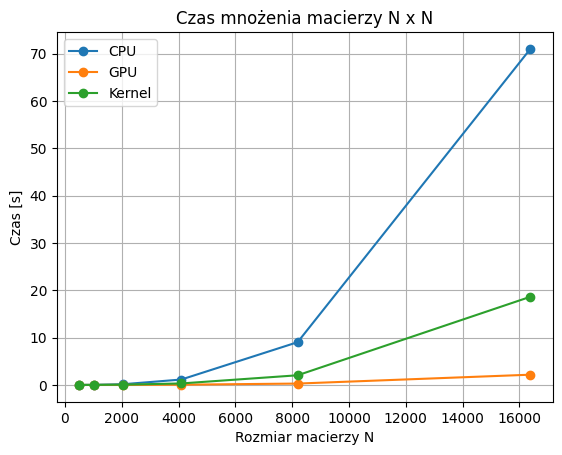

In [15]:
import matplotlib.pyplot as plt
import pycuda.driver as cuda
import pycuda.autoinit
from pycuda.compiler import SourceModule
import numpy as np
import time

def czas_cpu(N):
    A = np.random.rand(N, N).astype(np.float32)
    B = np.random.rand(N, N).astype(np.float32)
    start = time.time()
    np.matmul(A, B)
    return time.time() - start

def czas_gpu(N):
    A = cp.array(np.random.rand(N, N).astype(np.float32))
    B = cp.array(np.random.rand(N, N).astype(np.float32))
    cp.matmul(A, B); cp.cuda.Stream.null.synchronize()
    start = time.time()
    cp.matmul(A, B)
    cp.cuda.Stream.null.synchronize()
    return time.time() - start

def czas_kernel(N):
    A = np.random.rand(N, N).astype(np.float32)
    B = np.random.rand(N, N).astype(np.float32)
    C = np.empty((N, N), np.float32)
    A_g = cuda.mem_alloc(A.nbytes); B_g = cuda.mem_alloc(B.nbytes); C_g = cuda.mem_alloc(C.nbytes)
    cuda.memcpy_htod(A_g, A); cuda.memcpy_htod(B_g, B)
    block = (32, 32, 1)
    grid = ((N + 31) // 32, (N + 31) // 32, 1)
    start = time.time()
    matrixMul(A_g, B_g, C_g, np.int32(N), block=block, grid=grid)
    cuda.Context.synchronize()
    t = time.time() - start
    cuda.memcpy_dtoh(C, C_g)
    del A_g, B_g, C_g
    return t

rozmiary = [512, 1024, 2048, 4096, 8192, 16384]
t_cpu, t_gpu, t_kernel = [], [], []

for N in rozmiary:
    t_cpu.append(czas_cpu(N))
    t_gpu.append(czas_gpu(N))
    t_kernel.append(czas_kernel(N))
    print(f"N={N}: CPU={t_cpu[-1]:.5f}s, GPU={t_gpu[-1]:.5f}s, Kernel={t_kernel[-1]:.5f}s")

plt.plot(rozmiary, t_cpu, label="CPU")
plt.plot(rozmiary, t_gpu, label="GPU")
plt.plot(rozmiary, t_kernel, label="Kernel")
plt.xlabel("Rozmiar macierzy N")
plt.ylabel("Czas [s]")
plt.title("Czas mnożenia macierzy N x N")
plt.legend()
plt.grid()
plt.show()